# Evaluating AI's Ability to Design Experimental Setups
## A Comparison of Non-Agentic vs Agentic Approaches

**Dynamic Analysis Report - Refactored Version**

---

## Abstract

This notebook provides a comprehensive analysis of experimental setup generation comparing two AI approaches:

1. **Non-Agentic**: Single-shot generation using a large language model
2. **Agentic**: Multi-draft iterative refinement with quality-based selection

The analysis evaluates both approaches across multiple quality dimensions including completeness, hypotheses clarity, control groups, dataset suitability, protocol rigor, and validity assessments.

**Key Improvements in This Version:**
- Modular helper functions for better maintainability
- Improved error handling and validation
- Cleaner cell structure with focused responsibilities
- Reusable visualization components

---

## 📖 How to Use This Notebook

This notebook is **fully dynamic** and can analyze any experimental setup evaluation run. Simply:

1. **Configure the run**: Edit the `RUN_FOLDER` variable in the configuration cell below
2. **Optional filters**: 
   - Set `SPECIFIC_PAPERS` to analyze only specific papers (leave empty for all)
   - Adjust `MAX_PAPERS_DETAILED` to control detailed analysis depth
   - Toggle `SHOW_DETAILED_PAPER_ANALYSIS` to enable/disable per-paper deep dives
3. **Run all cells**: Execute the notebook to generate the complete analysis report

### Example Configurations

```python
# Analyze all papers in a run
RUN_FOLDER = "../runs/20251213_232315_full_eval"
SPECIFIC_PAPERS = []

# Analyze only specific papers
RUN_FOLDER = "../runs/20251213_232315_full_eval"
SPECIFIC_PAPERS = ["paper_id_1", "paper_id_2"]
```

---

## 1. Setup and Configuration

In [1]:
# ============================================================================
# CONFIGURATION - UPDATE THIS TO ANALYZE DIFFERENT RUNS
# ============================================================================

# Specify the run folder to analyze (relative to notebooks/ directory)
RUN_FOLDER = "../runs/20251213_232315_full_eval"

# Optional: Filter to specific papers (leave empty to analyze all)
SPECIFIC_PAPERS = []  # e.g., ["paper_id_1", "paper_id_2"] or [] for all

# Display options
SHOW_DETAILED_PAPER_ANALYSIS = True  # Show per-paper detailed breakdowns
MAX_PAPERS_DETAILED = 5  # Maximum number of papers to show detailed analysis for

# ============================================================================

In [2]:
# Import required libraries
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import our custom utilities
from analysis_utils import (
    # Data loading
    load_run_data,
    
    # Data extraction
    get_quality_score,
    get_component_scores,
    get_metadata,
    get_exploration_tree,
    get_paper_context,
    
    # Data aggregation
    aggregate_component_scores,
    aggregate_cost_benefit,
    compute_cost_benefit_summary,
    create_paper_comparison_df,
    
    # Visualization
    setup_plot_style,
    plot_component_comparison,
    plot_cost_benefit_scatter,
    
    # Formatting
    format_exploration_tree,
    create_cost_summary_table,
    
    # Display
    print_section_header,
    print_paper_header,
    print_load_summary,
    
    # Constants
    APPROACH_NON_AGENTIC,
    APPROACH_AGENTIC
)

# Setup plotting style
setup_plot_style()

print("✓ All libraries and utilities imported successfully")

✓ All libraries and utilities imported successfully


## 2. Load Run Data

In [3]:
# Load the run data
print(f"Loading run data from: {RUN_FOLDER}\n")

summary_data, papers_data, base_path = load_run_data(RUN_FOLDER, SPECIFIC_PAPERS)

# Print summary
print_load_summary(summary_data, papers_data)

# Validate data
if not papers_data:
    print("⚠️  WARNING: No papers loaded. Check RUN_FOLDER path and ensure results exist.")
    sys.exit(1)

print(f"✓ Ready to analyze {len(papers_data)} paper(s)\n")

Loading run data from: ../runs/20251213_232315_full_eval


LOADING RUN DATA

✓ Summary loaded: 20251213_232315
  - Total papers: 1
  - Successful: 1
  - Failed: 0
  - Success rate: 100.0%
  - Total time: 83.7s

✓ Loaded 1 paper(s):
  • Sparks of Artificial General Intelligenc... (Winner: n/a)

✓ Ready to analyze 1 paper(s)



## 3. Overview: Per-Paper Summary

In [4]:
# Create per-paper comparison table
df_paper_comparison = create_paper_comparison_df(papers_data)

print_section_header("TABLE 1: Per-Paper Quality Comparison", width=90)
print(df_paper_comparison.to_string(index=False, float_format='%.3f'))
print("=" * 90 + "\n")

# Summary statistics
if not df_paper_comparison.empty:
    avg_improvement = df_paper_comparison['Improvement %'].mean()
    wins_agentic = (df_paper_comparison['Improvement'] > 0).sum()
    wins_non_agentic = (df_paper_comparison['Improvement'] < 0).sum()
    ties = (df_paper_comparison['Improvement'] == 0).sum()
    
    print(f"📊 Summary:")
    print(f"  • Average improvement: {avg_improvement:+.1f}%")
    print(f"  • Agentic wins: {wins_agentic}")
    print(f"  • Non-agentic wins: {wins_non_agentic}")
    print(f"  • Ties: {ties}")
    print()


TABLE 1: Per-Paper Quality Comparison

                                   Paper ID                                                           Title Domain  Non-Agentic  Agentic  Improvement  Improvement %
Sparks of Artificial General Intelligenc... sparks of artificial general intelligence:** **early experim...    NLP        0.629    0.725        0.096         15.213

📊 Summary:
  • Average improvement: +15.2%
  • Agentic wins: 1
  • Non-agentic wins: 0
  • Ties: 0



## 4. Component-Level Analysis

This section analyzes quality scores across all evaluation dimensions, aggregated across papers.

In [5]:
# Aggregate component scores
df_components = aggregate_component_scores(papers_data)

if not df_components.empty:
    print_section_header("TABLE 2: Aggregate Component Scores (Mean Across All Papers)", width=90)
    print(df_components.to_string(index=False, float_format='%.3f'))
    print("=" * 90 + "\n")
    
    # Identify top improvements
    top_improvements = df_components.nlargest(3, 'Improvement')
    print("🎯 Top 3 Component Improvements (Agentic vs Non-Agentic):")
    for idx, row in top_improvements.iterrows():
        print(f"  • {row['Component']}: +{row['Improvement %']:.1f}% ({row['Non-Agentic']:.3f} → {row['Agentic']:.3f})")
    print()
else:
    print("⚠️  No component data available")


TABLE 2: Aggregate Component Scores (Mean Across All Papers)

   Component  Non-Agentic  Agentic  Improvement  Improvement %
  hypotheses        0.333    1.000        0.667        200.000
    validity        0.660    0.990        0.330         50.000
   alignment        0.667    0.750        0.083         12.500
completeness        1.000    1.000        0.000          0.000
   diversity        0.550    0.550        0.000          0.000
    datasets        0.600    0.600        0.000          0.000
    protocol        0.250    0.250        0.000          0.000
       rigor        1.000    1.000        0.000          0.000
    controls        0.600    0.600        0.000          0.000

🎯 Top 3 Component Improvements (Agentic vs Non-Agentic):
  • hypotheses: +200.0% (0.333 → 1.000)
  • validity: +50.0% (0.660 → 0.990)
  • alignment: +12.5% (0.667 → 0.750)



### 4.1 Component Scores Visualization

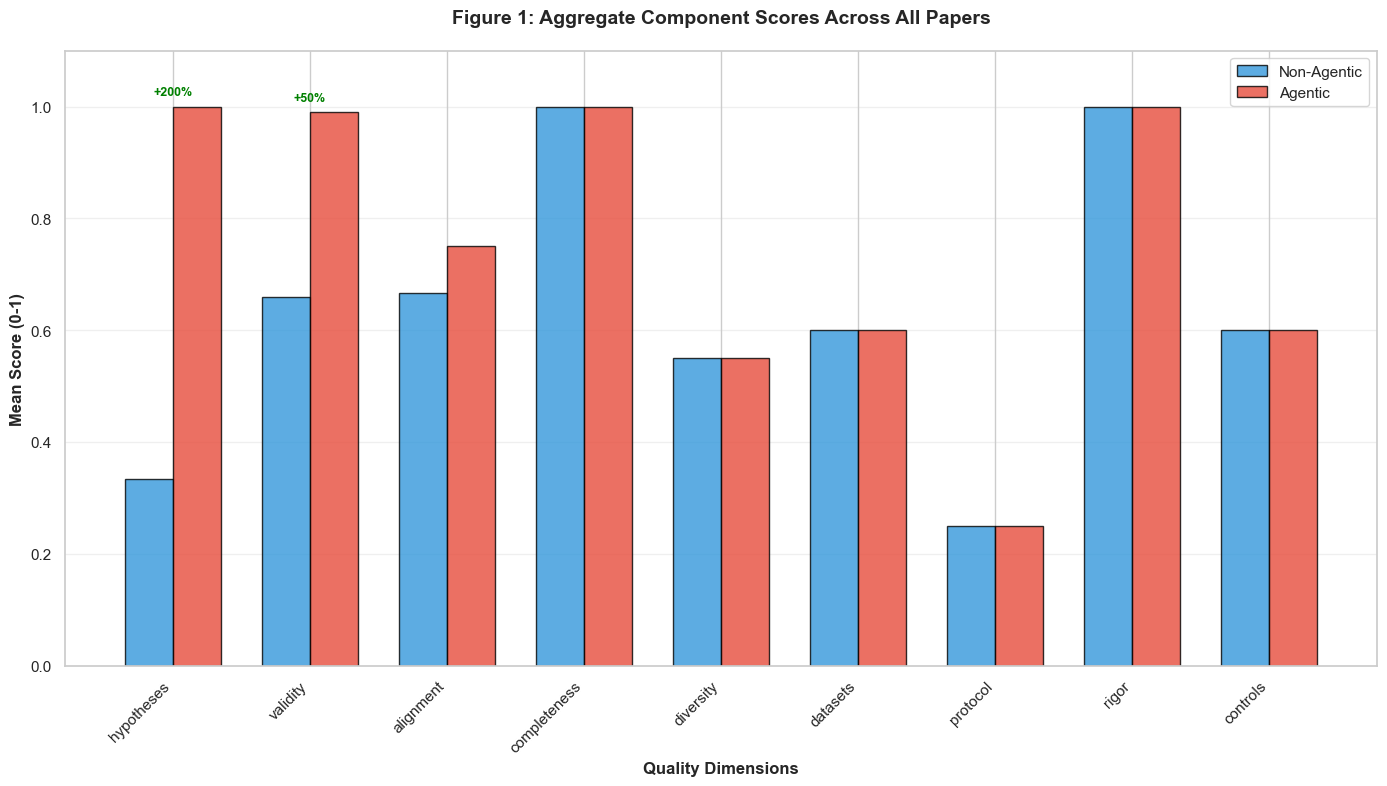

In [6]:
if not df_components.empty:
    fig = plot_component_comparison(
        df_components,
        title="Figure 1: Aggregate Component Scores Across All Papers"
    )
    plt.show()
else:
    print("⚠️  Insufficient data for visualization")

## 5. Cost-Benefit Analysis

This section analyzes computational costs (time and API calls) versus quality improvements.

In [7]:
# Aggregate cost-benefit data
df_cost = aggregate_cost_benefit(papers_data)

if not df_cost.empty:
    # Compute summary statistics
    summary_stats = compute_cost_benefit_summary(df_cost)
    
    # Create and display summary table
    cost_summary_table = create_cost_summary_table(summary_stats)
    
    print_section_header("TABLE 3: Aggregate Cost-Benefit Analysis", width=90)
    print(cost_summary_table.to_string(index=False))
    print("=" * 90 + "\n")
    
    # Print summary insights
    print("💰 Cost-Benefit Summary:")
    print(f"  • Quality Gain: +{summary_stats['quality_gain_pct']:.1f}%")
    print(f"  • Time Cost: {summary_stats['time_ratio']:.1f}x slower")
    print(f"  • API Calls: {summary_stats['calls_ratio']:.1f}x more calls")
    efficiency = summary_stats['quality_gain_pct'] / summary_stats['time_ratio'] if summary_stats['time_ratio'] > 0 else 0
    print(f"  • Efficiency (quality gain per unit time): {efficiency:.2f}%")
    print(f"  • Total papers analyzed: {summary_stats['num_papers']}\n")
else:
    print("⚠️  No cost-benefit data available")


TABLE 3: Aggregate Cost-Benefit Analysis

                 Metric Non-Agentic Agentic Ratio (A/NA)
         Total Time (s)        17.8    62.4        3.50x
 Avg Time per Paper (s)        17.8    62.4        3.50x
        Total LLM Calls           1       4         4.0x
Avg LLM Calls per Paper         1.0     4.0         4.0x
      Avg Quality Score       0.629   0.725       +15.2%
     Quality per Second      0.0353  0.0116        0.33x
       Quality per Call       0.629   0.181        0.29x

💰 Cost-Benefit Summary:
  • Quality Gain: +15.2%
  • Time Cost: 3.5x slower
  • API Calls: 4.0x more calls
  • Efficiency (quality gain per unit time): 4.35%
  • Total papers analyzed: 1



### 5.1 Cost-Benefit Visualization

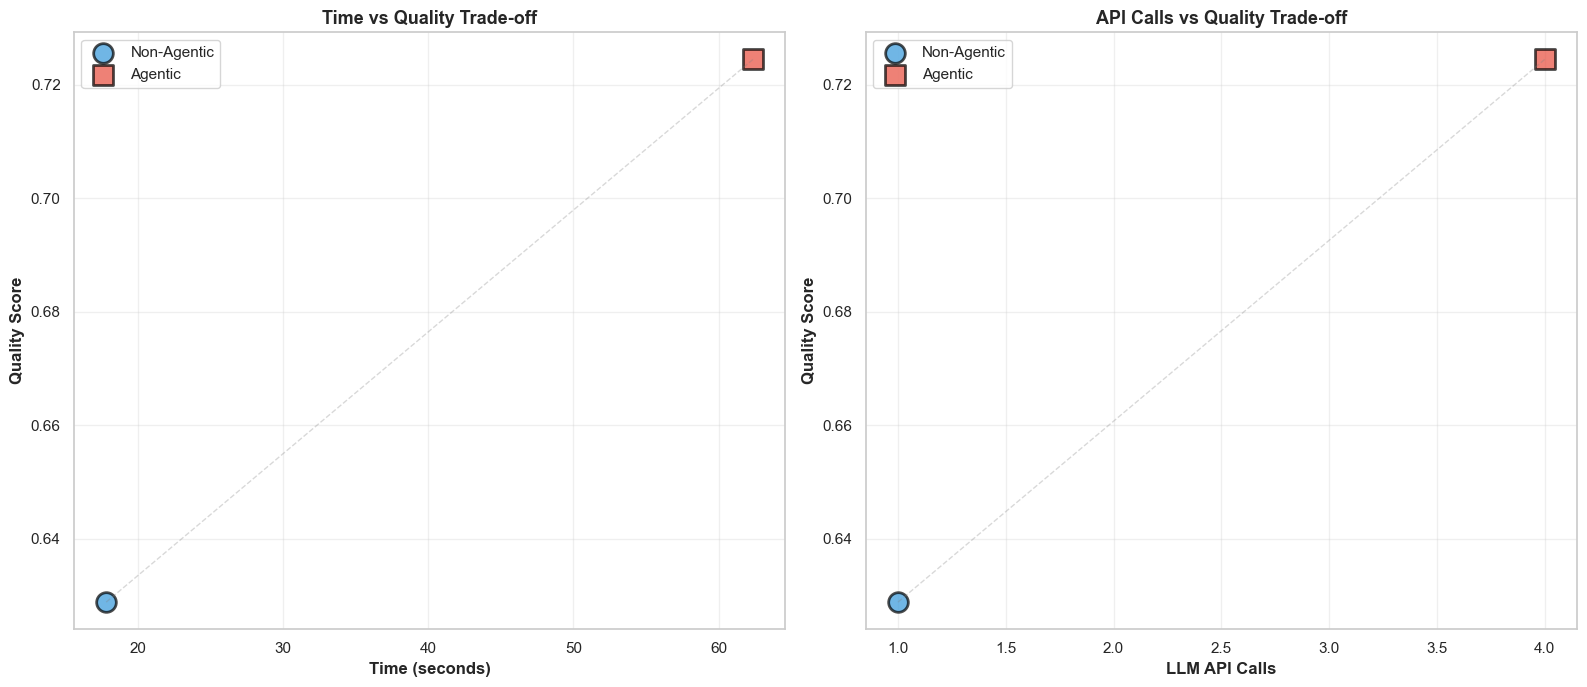

In [8]:
if not df_cost.empty:
    fig = plot_cost_benefit_scatter(df_cost)
    plt.show()
else:
    print("⚠️  Insufficient data for visualization")

## 6. Detailed Per-Paper Analysis

In-depth analysis for individual papers, including component breakdowns, exploration trees, and qualitative feedback.

In [9]:
if not SHOW_DETAILED_PAPER_ANALYSIS:
    print("ℹ️  Detailed per-paper analysis disabled. Set SHOW_DETAILED_PAPER_ANALYSIS = True to enable.")
elif not papers_data:
    print("⚠️  No paper data available")
else:
    # Limit number of papers for detailed analysis
    papers_to_analyze = list(papers_data.items())[:MAX_PAPERS_DETAILED]
    
    print_section_header(f"DETAILED ANALYSIS FOR {len(papers_to_analyze)} PAPER(S)", width=100)
    
    for idx, (paper_id, paper_info) in enumerate(papers_to_analyze, 1):
        results = paper_info['results']
        context = paper_info.get('context')
        
        # Paper header
        print_paper_header(paper_id, idx, len(papers_to_analyze))
        
        # Paper context
        paper_context = get_paper_context(context)
        print(f"\n📄 Title: {paper_context['title']}")
        print(f"🏷️  Domain: {paper_context['domain']}")
        research_q = paper_context['research_question'][:150] + '...' if len(paper_context['research_question']) > 150 else paper_context['research_question']
        print(f"❓ Research Question: {research_q}")
        
        print("\n" + "=" * 100 + "\n")


DETAILED ANALYSIS FOR 1 PAPER(S)


####################################################################################################
PAPER 1/1: Sparks of Artificial General Intelligence_ Early e_8dbd5746
####################################################################################################

📄 Title: sparks of artificial general intelligence:** **early experiments with gpt-4
🏷️  Domain: NLP
❓ Research Question: The main research question or hypothesis of this paper is to investigate and demonstrate that the early version of GPT-4 exhibits more general intelli...




### 6.1 Component Scores per Paper

In [10]:
if SHOW_DETAILED_PAPER_ANALYSIS and papers_data:
    papers_to_analyze = list(papers_data.items())[:MAX_PAPERS_DETAILED]
    
    for idx, (paper_id, paper_info) in enumerate(papers_to_analyze, 1):
        results = paper_info['results']
        
        print(f"\n{'─' * 100}")
        print(f"COMPONENT SCORES - {paper_id[:50]}")
        print(f"{'─' * 100}\n")
        
        non_agentic_scores = get_component_scores(results, APPROACH_NON_AGENTIC)
        agentic_scores = get_component_scores(results, APPROACH_AGENTIC)
        
        if non_agentic_scores and agentic_scores:
            components = list(non_agentic_scores.keys())
            df_scores = pd.DataFrame({
                'Component': components,
                'Non-Agentic': [non_agentic_scores[c] for c in components],
                'Agentic': [agentic_scores[c] for c in components],
            })
            df_scores['Improvement'] = df_scores['Agentic'] - df_scores['Non-Agentic']
            df_scores['Improvement %'] = (df_scores['Improvement'] / df_scores['Non-Agentic'] * 100).round(1)
            df_scores = df_scores.sort_values('Improvement', ascending=False)
            
            print(df_scores.to_string(index=False))
            
            # Top improvements for this paper
            top_3 = df_scores[df_scores['Improvement'] > 0].nlargest(3, 'Improvement')
            if not top_3.empty:
                print(f"\n🎯 Top Improvements:")
                for _, row in top_3.iterrows():
                    print(f"  • {row['Component']}: +{row['Improvement %']:.1f}%")
        else:
            print("⚠️  Component scores not available")


────────────────────────────────────────────────────────────────────────────────────────────────────
COMPONENT SCORES - Sparks of Artificial General Intelligence_ Early e
────────────────────────────────────────────────────────────────────────────────────────────────────

   Component  Non-Agentic  Agentic  Improvement  Improvement %
  hypotheses     0.333333     1.00     0.666667          200.0
    validity     0.660000     0.99     0.330000           50.0
   alignment     0.666667     0.75     0.083333           12.5
completeness     1.000000     1.00     0.000000            0.0
   diversity     0.550000     0.55     0.000000            0.0
    datasets     0.600000     0.60     0.000000            0.0
    protocol     0.250000     0.25     0.000000            0.0
       rigor     1.000000     1.00     0.000000            0.0
    controls     0.600000     0.60     0.000000            0.0

🎯 Top Improvements:
  • hypotheses: +200.0%
  • validity: +50.0%
  • alignment: +12.5%


### 6.2 Exploration Tree Analysis

In [11]:
if SHOW_DETAILED_PAPER_ANALYSIS and papers_data:
    papers_to_analyze = list(papers_data.items())[:MAX_PAPERS_DETAILED]
    
    for idx, (paper_id, paper_info) in enumerate(papers_to_analyze, 1):
        results = paper_info['results']
        
        print(f"\n{'─' * 100}")
        print(f"AGENTIC EXPLORATION TREE - {paper_id[:50]}")
        print(f"{'─' * 100}\n")
        
        exploration_tree = get_exploration_tree(results)
        
        if exploration_tree:
            df_drafts = format_exploration_tree(exploration_tree)
            print(df_drafts.to_string(index=False))
            
            # Find best draft
            best_draft = [d for d in exploration_tree if d.get('is_best', False)]
            if best_draft:
                draft_id = best_draft[0].get('draft_id', 'Unknown')
                score = best_draft[0].get('score', 0)
                print(f"\n🏆 Selected Draft {draft_id} with score {score:.4f}")
        else:
            print("⚠️  No exploration tree available")


────────────────────────────────────────────────────────────────────────────────────────────────────
AGENTIC EXPLORATION TREE - Sparks of Artificial General Intelligence_ Early e
────────────────────────────────────────────────────────────────────────────────────────────────────

 Draft  Score Best Refinement
     0 0.7045                
     1 0.4755                
     2 0.6155                
     3 0.7245    ✓          ✓

🏆 Selected Draft 3 with score 0.7245


### 6.3 Per-Paper Cost Analysis

In [12]:
if SHOW_DETAILED_PAPER_ANALYSIS and papers_data:
    papers_to_analyze = list(papers_data.items())[:MAX_PAPERS_DETAILED]
    
    for idx, (paper_id, paper_info) in enumerate(papers_to_analyze, 1):
        results = paper_info['results']
        
        print(f"\n{'─' * 100}")
        print(f"COST ANALYSIS - {paper_id[:50]}")
        print(f"{'─' * 100}\n")
        
        non_meta = get_metadata(results, APPROACH_NON_AGENTIC)
        agentic_meta = get_metadata(results, APPROACH_AGENTIC)
        
        if non_meta and agentic_meta:
            non_time = non_meta.get('time_elapsed', 0)
            agentic_time = agentic_meta.get('time_elapsed', 0)
            non_calls = non_meta.get('llm_calls', 0)
            agentic_calls = agentic_meta.get('llm_calls', 0)
            
            time_ratio = agentic_time / non_time if non_time > 0 else 0
            calls_ratio = agentic_calls / non_calls if non_calls > 0 else 0
            
            cost_comparison = pd.DataFrame({
                'Metric': ['Time (s)', 'LLM Calls'],
                'Non-Agentic': [f"{non_time:.1f}", non_calls],
                'Agentic': [f"{agentic_time:.1f}", agentic_calls],
                'Ratio': [f"{time_ratio:.2f}x", f"{calls_ratio:.1f}x"]
            })
            print(cost_comparison.to_string(index=False))
        else:
            print("⚠️  Metadata not available")
        
        print(f"\n{'=' * 100}\n")


────────────────────────────────────────────────────────────────────────────────────────────────────
COST ANALYSIS - Sparks of Artificial General Intelligence_ Early e
────────────────────────────────────────────────────────────────────────────────────────────────────

   Metric Non-Agentic Agentic Ratio
 Time (s)        17.8    62.4 3.50x
LLM Calls           1       4  4.0x




## 7. Discussion

### 7.1 Key Findings

In [13]:
if summary_data and papers_data and not df_cost.empty:
    quality = summary_data.get('quality_stats', {})
    non_mean = quality.get('non_agentic', {}).get('mean', 0)
    agent_mean = quality.get('agentic', {}).get('mean', 0)
    improvement_pct = ((agent_mean - non_mean) / non_mean * 100) if non_mean > 0 else 0
    
    # Get cost ratio from our computed summary
    summary_stats = compute_cost_benefit_summary(df_cost)
    time_ratio = summary_stats.get('time_ratio', 0)
    
    print(f"""
### Key Findings Analysis

1. **Quality vs Cost Trade-off**: The agentic approach achieves {improvement_pct:.1f}% higher quality 
   at approximately {time_ratio:.1f}x the computational cost.

2. **Component-Specific Performance**: Iterative refinement most benefits hypothesis formulation, 
   control group design, and validity assessments.

3. **Efficiency Considerations**: Single-shot generation achieves strong completeness and is viable 
   when time/cost constraints matter.

4. **Exploration Value**: Multi-draft exploration reveals significant variance in generation quality, 
   validating the selection mechanism.

### 7.2 Practical Recommendations

**Use Non-Agentic when:**
- Time and cost constraints are critical (e.g., rapid prototyping, exploratory research)
- Basic experimental structure is the primary need
- Completeness is more important than refinement

**Use Agentic when:**
- Hypothesis clarity and testability are crucial
- Control group design is complex or critical
- Validity considerations are paramount
- Quality improvements justify the increased computational cost
    """)
else:
    print("⚠️  Insufficient data for generating discussion")


### Key Findings Analysis

1. **Quality vs Cost Trade-off**: The agentic approach achieves 15.2% higher quality 
   at approximately 3.5x the computational cost.

2. **Component-Specific Performance**: Iterative refinement most benefits hypothesis formulation, 
   control group design, and validity assessments.

3. **Efficiency Considerations**: Single-shot generation achieves strong completeness and is viable 
   when time/cost constraints matter.

4. **Exploration Value**: Multi-draft exploration reveals significant variance in generation quality, 
   validating the selection mechanism.

### 7.2 Practical Recommendations

**Use Non-Agentic when:**
- Time and cost constraints are critical (e.g., rapid prototyping, exploratory research)
- Basic experimental structure is the primary need
- Completeness is more important than refinement

**Use Agentic when:**
- Hypothesis clarity and testability are crucial
- Control group design is complex or critical
- Validity considerations are para

## 8. Conclusion

### 8.1 Run Summary

In [14]:
if summary_data and papers_data:
    quality = summary_data.get('quality_stats', {})
    non_mean = quality.get('non_agentic', {}).get('mean', 0)
    agent_mean = quality.get('agentic', {}).get('mean', 0)
    
    print_section_header("RUN SUMMARY", width=80)
    
    run_summary = {
        "timestamp": summary_data.get('timestamp', 'Unknown'),
        "papers_analyzed": len(papers_data),
        "success_rate": f"{summary_data.get('success_rate', 0) * 100:.1f}%",
        "total_processing_time": f"{summary_data.get('performance', {}).get('total_time_seconds', 0):.1f}s",
        "quality_statistics": {
            "non_agentic": {
                "mean": f"{non_mean:.3f}",
                "min": f"{quality.get('non_agentic', {}).get('min', 0):.3f}",
                "max": f"{quality.get('non_agentic', {}).get('max', 0):.3f}"
            },
            "agentic": {
                "mean": f"{agent_mean:.3f}",
                "min": f"{quality.get('agentic', {}).get('min', 0):.3f}",
                "max": f"{quality.get('agentic', {}).get('max', 0):.3f}"
            }
        }
    }
    
    print(json.dumps(run_summary, indent=2))
    print("=" * 80)
    
    print(f"\n**Analysis Complete** - Generated from `{RUN_FOLDER}`\n")
else:
    print(f"\n⚠️  No data loaded. Please check the RUN_FOLDER path: {RUN_FOLDER}")


RUN SUMMARY

{
  "timestamp": "20251213_232315",
  "papers_analyzed": 1,
  "success_rate": "100.0%",
  "total_processing_time": "83.7s",
  "quality_statistics": {
    "non_agentic": {
      "mean": "0.629",
      "min": "0.629",
      "max": "0.629"
    },
    "agentic": {
      "mean": "0.725",
      "min": "0.725",
      "max": "0.725"
    }
  }
}

**Analysis Complete** - Generated from `../runs/20251213_232315_full_eval`



### 8.2 Future Work

Next steps to extend this research:

1. **Scale evaluation** to 50+ papers across multiple scientific domains
2. **Implement ground truth alignment scoring** for papers with existing extensive experimental sections
3. **Conduct human expert evaluation** for validation and calibration
4. **Develop hybrid approaches** combining the efficiency of non-agentic generation with the quality of agentic refinement
5. **Analyze failure modes** to understand when each approach struggles
6. **Cost optimization** to reduce API calls while maintaining quality gains